# 03 Explore Layer 2 data

Step 2 of the Layer 2 work. This notebook only looks at the data. It builds no models and changes no files.

Files in `data/raw/philippines/`:
- `palay_areas.csv`, `palay_production.csv`, `corn_area.csv`, `corn_production.csv`: PSA OpenSTAT tables, quarterly, 1987 to 2026. Area in hectares, production in metric tons.
- `phl-rainfall-subnat-full.csv`: CHIRPS rainfall every ten days, 1981 to November 2026, by region and province (PCODE).

Questions this notebook answers:
1. After the agreed cleaning, is anything lost? (Check against the national total.)
2. How many years of usable yield does each province and crop have? This feeds the "minimum data" decision. The notebook does not pick the number.
3. How do two candidate rules for turning ten-day rainfall into quarters compare? The notebook does not pick a rule.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PH_DIR = Path("../data/raw/philippines")
CROP_FILES = {
    "area": ["palay_areas.csv", "corn_area.csv"],
    "production": ["palay_production.csv", "corn_production.csv"],
}
RAIN_PATH = PH_DIR / "phl-rainfall-subnat-full.csv"
ENSO_PATH = Path("../data/processed/enso_monthly.csv")

## 1. Load the crop tables

Each file has a title line and a blank line before the header, so we skip 2 rows. Missing values are written as `..`.

The `Geolocation` column marks the level with leading dots: no dots is the country, two dots a region, four dots a province or city. We keep the country row (for the check in section 2) and the four-dot rows. We keep only the quarter columns, not the semester or annual totals, and reshape to one row per crop type, location, year and quarter.

In [2]:
def read_crop_table(file_name, value_name):
    wide = pd.read_csv(PH_DIR / file_name, sep=";", skiprows=2, na_values="..")
    wide = wide.rename(columns={"Ecosystem/Croptype": "crop_type", "Geolocation": "location"})
    quarter_cols = [c for c in wide.columns if "Quarter" in c]
    long = wide.melt(id_vars=["crop_type", "location"], value_vars=quarter_cols,
                     var_name="period", value_name=value_name)
    long["year"] = long["period"].str[:4].astype(int)
    long["quarter"] = long["period"].str[-1].astype(int)
    return long.drop(columns="period")


keys = ["crop_type", "location", "year", "quarter"]
area = pd.concat([read_crop_table(f, "area") for f in CROP_FILES["area"]])
production = pd.concat([read_crop_table(f, "production") for f in CROP_FILES["production"]])
crops_raw = area.merge(production, on=keys, how="outer")

print("Rows:", len(crops_raw))
print("Crop types:", crops_raw["crop_type"].unique().tolist())
print("Years:", crops_raw["year"].min(), "to", crops_raw["year"].max())
print("Locations:", crops_raw["location"].nunique())
crops_raw.head()

Rows: 104640
Crop types: ['Corn', 'Irrigated Palay', 'Palay', 'Rainfed Palay', 'White Corn', 'Yellow Corn']
Years: 1987 to 2026
Locations: 109


,crop_type,location,area,year,quarter,production
0,Corn,....Abra,1120.0,1987,1,725.0
1,Corn,....Abra,30.0,1987,2,35.0
2,Corn,....Abra,6740.0,1987,3,6695.0
3,Corn,....Abra,0.0,1987,4,0.0
4,Corn,....Abra,1250.0,1988,1,910.0


## 2. Clean the province rows

Agreed rules (decided with the user):
- Strip the leading dots and the footnote marks (`a/`, `b/`, `c/`).
- Negros Occidental, Negros Oriental and Siquijor each have an old row (1987 to 2023) and a footnoted row under the Negros Island Region (2024 on). Once the footnote is stripped they share a name, so summing by name joins them. The years do not overlap.
- `Sulu c/` (under Region IX) is empty, so it is dropped.
- Maguindanao del Norte (data from 2024) is merged with Maguindanao del Sur (which holds the old combined history) as "Maguindanao", because the rainfall file has only the old combined area.
- Davao Occidental (data from 2019) is merged into Davao del Sur for the same reason.
- The five city rows are counted separately from their provinces, so they are added in. Area and production are summed first, then yield is computed.
- Three names are changed to match the map shapes.

In [3]:
RENAME = {
    # merged provinces (rainfall uses the old combined areas)
    "Maguindanao del Norte": "Maguindanao",
    "Maguindanao del Sur": "Maguindanao",
    "Davao Occidental": "Davao del Sur",
    # city rows added into their province
    "Bacolod City": "Negros Occidental",
    "Butuan City": "Agusan del Norte",
    "City of Davao": "Davao del Sur",
    "Puerto Princesa City": "Palawan",
    "Zamboanga City": "Zamboanga del Sur",
    # names that differ from the map shapes
    "Cotabato (North Cotabato)": "Cotabato",
    "Davao de Oro (Compostela Valley)": "Davao de Oro",
    "Tawi-tawi": "Tawi-Tawi",
}

provinces = crops_raw[crops_raw["location"].str.startswith("....")].copy()
provinces = provinces[provinces["location"] != "....Sulu c/"]
provinces["province"] = (
    provinces["location"].str.strip(".").str.replace(r"\s*[a-d]/$", "", regex=True).str.strip()
)
provinces["province"] = provinces["province"].replace(RENAME)

# min_count=1 keeps a quarter missing when every row being summed is missing.
crops = (
    provinces.groupby(["crop_type", "province", "year", "quarter"])[["area", "production"]]
    .sum(min_count=1)
    .reset_index()
)
print("Provinces after cleaning:", crops["province"].nunique())
print(sorted(crops["province"].unique()))

Provinces after cleaning:

 80
['Abra', 'Agusan del Norte', 'Agusan del Sur', 'Aklan', 'Albay', 'Antique', 'Apayao', 'Aurora', 'Basilan', 'Bataan', 'Batanes', 'Batangas', 'Benguet', 'Biliran', 'Bohol', 'Bukidnon', 'Bulacan', 'Cagayan', 'Camarines Norte', 'Camarines Sur', 'Camiguin', 'Capiz', 'Catanduanes', 'Cavite', 'Cebu', 'Cotabato', 'Davao Oriental', 'Davao de Oro', 'Davao del Norte', 'Davao del Sur', 'Dinagat Islands', 'Eastern Samar', 'Guimaras', 'Ifugao', 'Ilocos Norte', 'Ilocos Sur', 'Iloilo', 'Isabela', 'Kalinga', 'La Union', 'Laguna', 'Lanao del Norte', 'Lanao del Sur', 'Leyte', 'Maguindanao', 'Marinduque', 'Masbate', 'Misamis Occidental', 'Misamis Oriental', 'Mountain Province', 'Negros Occidental', 'Negros Oriental', 'Northern Samar', 'Nueva Ecija', 'Nueva Vizcaya', 'Occidental Mindoro', 'Oriental Mindoro', 'Palawan', 'Pampanga', 'Pangasinan', 'Quezon', 'Quirino', 'Rizal', 'Romblon', 'Samar', 'Sarangani', 'Siquijor', 'Sorsogon', 'South Cotabato', 'Southern Leyte', 'Sultan Kudarat', 'Sulu', 'Surigao de

**Check:** nothing should be lost. For every crop type, year and quarter, the sum of the cleaned provinces should equal the `PHILIPPINES` row. A small tolerance allows for rounding in the PSA table.

The regions always add up to the national total. But from 2023 on, the BARMM region total is larger than the sum of its province rows. That part of BARMM is not in any province row, so no cleaning can recover it. The check below measures that BARMM gap and confirms it explains every mismatch.

In [4]:
TOTAL_KEYS = ["crop_type", "year", "quarter"]
VALUES = ["area", "production"]
BARMM = "..BANGSAMORO AUTONOMOUS REGION IN MUSLIM MINDANAO (BARMM)d/"
BARMM_PROVINCES = ["....Basilan", "....Lanao del Sur", "....Maguindanao del Norte",
                   "....Maguindanao del Sur", "....Sulu", "....Tawi-tawi"]


def totals(rows):
    return rows.groupby(TOTAL_KEYS)[VALUES].sum(min_count=1)


national = totals(crops_raw[crops_raw["location"] == "PHILIPPINES"])
province_sum = totals(crops)
barmm_gap = totals(crops_raw[crops_raw["location"] == BARMM]).sub(
    totals(crops_raw[crops_raw["location"].isin(BARMM_PROVINCES)]), fill_value=0)

for col in VALUES:
    gap = (national[col] - province_sum[col]).dropna()
    off = gap.abs() > 1 + 0.001 * national[col].reindex(gap.index).abs()
    unexplained = (gap - barmm_gap[col].reindex(gap.index).fillna(0)).abs()
    print(f"{col}: {len(gap)} quarters, off by more than tolerance: {off.sum()}, "
          f"years: {sorted(gap[off].index.get_level_values('year').unique())}, "
          f"largest gap after removing the BARMM gap: {unexplained.max():.2f}")
    assert (unexplained <= 1 + 0.001 * national[col].reindex(gap.index).abs()).all(), "Gap not explained by BARMM"
print("OK: every mismatch is the BARMM area that has no province row.")

area: 954 quarters, off by more than tolerance: 89, years: [2023, 2024, 2025, 2026], largest gap after removing the BARMM gap: 117.01
production: 954 quarters, off by more than tolerance: 84, years: [2023, 2024, 2025, 2026], largest gap after removing the BARMM gap: 275.01
OK: every mismatch is the BARMM area that has no province row.


In [5]:
print("BARMM area and production not in any province row, per year (all quarters summed):")
barmm_gap[barmm_gap.index.get_level_values("year") >= 2022].groupby(["crop_type", "year"]).sum().round(0)

BARMM area and production not in any province row, per year (all quarters summed):


area  production
crop_type       year                     
Corn            2022      0.0        -0.0
                2023  26685.0     66466.0
                2024  23423.0     58133.0
                2025  21756.0     68236.0
                2026  16000.0     55448.0
Irrigated Palay 2022      0.0         0.0
                2023  12217.0     35746.0
                2024  14396.0     47997.0
                2025  14972.0     49260.0
                2026   8620.0     25951.0
Palay           2022      0.0        -0.0
                2023  16466.0     45159.0
                2024  19511.0     61083.0
                2025  20203.0     62659.0
                2026  10783.0     30621.0
Rainfed Palay   2022      0.0         0.0
                2023   4249.0      9413.0
                2024   5115.0     13086.0
                2025   5231.0     13399.0
                2026   2163.0      4670.0
White Corn      2022      0.0         0.0
                2023   4607.0      8990.0
                2024   2582.0      5038.0
                2025   2320.0      5354.0
                2026   1573.0      3787.0
Yellow Corn     2022      0.0        -0.0
                2023  22078.0     57476.0
                2024  20841.0     53095.0
                2025  19436.0     62882.0
                2026  14427.0     51661.0

**Yield** = production / area, only where area > 0. A zero area means the crop was not grown that quarter, so the yield is missing, not zero.

In [6]:
crops["yield_t_per_ha"] = (crops["production"] / crops["area"]).where(crops["area"] > 0)
print("Quarters with area = 0:", (crops["area"] == 0).sum())
print("Quarters with area missing:", crops["area"].isna().sum())
print("Quarters with a yield:", crops["yield_t_per_ha"].notna().sum(), "of", len(crops))
crops["yield_t_per_ha"].describe()

Quarters with area = 0: 9623
Quarters with area missing: 492
Quarters with a yield: 66685 of 76800


count    66685.000000
mean         2.618447
std          1.294049
min          0.056911
25%          1.532301
50%          2.640026
75%          3.563380
max          9.132653
Name: yield_t_per_ha, dtype: float64

## 3. How much usable data is there?

A "usable year" for a province, crop type and quarter is a year with area > 0 and a yield. Counted two ways:
- **Cell:** province + crop type + calendar quarter (for example Nueva Ecija, Palay, Quarter 3). This is the strict count if each quarter gets its own normal.
- **Pair:** province + crop type. A year counts if at least one quarter has a yield.

Possible years: 1987 to 2026 (40, but 2026 Quarter 4 is not out yet).

In [7]:
usable = crops[crops["yield_t_per_ha"].notna()]
cell_years = usable.groupby(["province", "crop_type", "quarter"])["year"].nunique()
pair_years = usable.groupby(["province", "crop_type"])["year"].nunique()

all_cells = crops.groupby(["province", "crop_type", "quarter"]).size().index
all_pairs = crops.groupby(["province", "crop_type"]).size().index
cell_years = cell_years.reindex(all_cells, fill_value=0)
pair_years = pair_years.reindex(all_pairs, fill_value=0)

thresholds = [5, 10, 15, 20, 30]
summary = pd.DataFrame({
    "min_years": thresholds,
    "pairs_ok": [(pair_years >= n).sum() for n in thresholds],
    "cells_ok": [(cell_years >= n).sum() for n in thresholds],
})
print("Total pairs:", len(pair_years), " total cells:", len(cell_years))
summary

Total pairs: 480  total cells: 1920


,min_years,pairs_ok,cells_ok
0,5,476,1854
1,10,475,1839
2,15,473,1806
3,20,462,1765
4,30,441,1586


In [8]:
by_crop = pd.DataFrame({
    f">={n}y": (cell_years >= n).groupby(level="crop_type").sum() for n in thresholds
})
by_crop["cells"] = cell_years.groupby(level="crop_type").size()
print("Cells passing each threshold, by crop type:")
by_crop

Cells passing each threshold, by crop type:


,>=5y,>=10y,>=15y,>=20y,>=30y,cells
crop_type,,,,,,
Corn,318,318,314,307,286,320
Irrigated Palay,310,309,308,304,296,320
Palay,314,314,312,307,298,320
Rainfed Palay,291,281,272,264,233,320
White Corn,315,315,309,304,267,320
Yellow Corn,306,302,291,279,206,320


In [9]:
print("Pairs with the least data (years with any usable quarter):")
pair_years.sort_values().head(15)

Pairs with the least data (years with any usable quarter):


province         crop_type      
Tawi-Tawi        Irrigated Palay     0
Basilan          Yellow Corn         0
Tawi-Tawi        Yellow Corn         1
Sulu             Yellow Corn         2
Batanes          Irrigated Palay     5
Sulu             Irrigated Palay    12
Dinagat Islands  Yellow Corn        13
Batanes          Palay              15
                 White Corn         15
                 Yellow Corn        15
                 Rainfed Palay      15
                 Corn               15
Dinagat Islands  Irrigated Palay    18
                 Palay              18
                 Corn               18
Name: year, dtype: int64

In [10]:
print("Usable years per calendar quarter (median over province-crop pairs):")
cell_years.groupby(level="quarter").median()

Usable years per calendar quarter (median over province-crop pairs):


quarter
1    40.0
2    40.0
3    40.0
4    39.0
Name: year, dtype: float64

## 4. Rainfall (CHIRPS)

Columns used here:
- `rfh`: rainfall in the ten-day period (mm).
- `rfh_avg`: the long-term average for the same ten days (mm).
- `rfq`: rainfall anomaly, `rfh` as a percent of normal.
- `adm_level`: 1 = region, 2 = province. Provinces are identified by `PCODE`.
- `version`: `final` or `prelim` (preliminary, may still change).

In [11]:
rain_raw = pd.read_csv(RAIN_PATH, parse_dates=["date"])
print("Rows:", len(rain_raw))
print("Dates:", rain_raw["date"].min().date(), "to", rain_raw["date"].max().date())
print("Areas per level:", rain_raw.groupby("adm_level")["PCODE"].nunique().to_dict())
print("Version counts:", rain_raw["version"].value_counts().to_dict())
prelim = rain_raw[rain_raw["version"] == "prelim"]
print("Preliminary rows run from", prelim["date"].min().date(), "to", prelim["date"].max().date())
print("Missing values per column:")
rain_raw[["rfh", "rfh_avg", "rfq"]].isna().sum()

Rows: 161798
Dates: 1981-01-01 to 2026-11-01
Areas per level: {1: 17, 2: 81}
Version counts: {'final': 161406, 'prelim': 392}
Preliminary rows run from 2026-10-01 to 2026-11-01
Missing values per column:


rfh        0
rfh_avg    0
rfq        0
dtype: int64

Each month has three rows: the 1st, 11th and 21st (ten-day periods). A calendar quarter (Q1 = January to March) therefore holds 9 rows. Example: Nueva Ecija (`PH03049`), Quarter 1 of 2015.

In [12]:
rain = rain_raw[rain_raw["adm_level"] == 2].copy()
rain["year"] = rain["date"].dt.year
rain["quarter"] = rain["date"].dt.quarter

example = rain[(rain["PCODE"] == "PH03049") & (rain["year"] == 2015) & (rain["quarter"] == 1)]
example[["date", "rfh", "rfh_avg", "rfq", "version"]]

,date,rfh,rfh_avg,rfq,version
128351,2015-01-01,6.366120,12.531330,64.833190,final
128352,2015-01-11,27.961748,13.800547,175.323350,final
128353,2015-01-21,5.557377,14.953188,52.910730,final
128354,2015-02-01,4.672131,11.944445,57.081425,final
128355,2015-02-11,6.579235,11.007468,72.336460,final
128356,2015-02-21,3.546448,9.726412,58.034824,final
128357,2015-03-01,5.961749,15.031512,54.722520,final
128358,2015-03-11,7.639344,13.268670,69.185905,final
128359,2015-03-21,11.114754,23.873589,55.811398,final


**Two candidate rules** for one rainfall value per province and quarter (not decided):
- **Rule A, total vs normal:** 100 × sum of `rfh` / sum of `rfh_avg`. One wet ten-day period counts by its millimetres.
- **Rule B, mean of rfq:** the average of the nine ten-day percentages. Each period counts equally, so a dry period in the dry season (small normal, big percentage swing) weighs as much as one in the wet season.

Both are percent of normal (100 = normal). Rainfall starts in 1981 and crops in 1987, so the rainfall has six extra years that can help define "normal".

In [13]:
quarter_rain = rain.groupby(["PCODE", "year", "quarter"]).agg(
    rfh_sum=("rfh", "sum"),
    rfh_avg_sum=("rfh_avg", "sum"),
    rule_b_mean_rfq=("rfq", "mean"),
    periods=("rfh", "size"),
).reset_index()
quarter_rain["rule_a_pct"] = 100 * quarter_rain["rfh_sum"] / quarter_rain["rfh_avg_sum"]

print("Quarters with fewer than 9 periods (incomplete):", (quarter_rain["periods"] < 9).sum())
full = quarter_rain[quarter_rain["periods"] == 9]
diff = (full["rule_a_pct"] - full["rule_b_mean_rfq"]).abs()
print(f"Complete quarters: {len(full)}")
print(f"Correlation between rules: {full['rule_a_pct'].corr(full['rule_b_mean_rfq']):.3f}")
print(f"Mean absolute difference: {diff.mean():.1f} points, 95th percentile {diff.quantile(0.95):.1f} points")

Quarters with fewer than 9 periods (incomplete): 81
Complete quarters: 14823
Correlation between rules: 0.952
Mean absolute difference: 6.3 points, 95th percentile 21.9 points


In [14]:
nueva_ecija = full[(full["PCODE"] == "PH03049") & full["year"].between(2014, 2016)]
nueva_ecija[["year", "quarter", "rfh_sum", "rfh_avg_sum", "rule_a_pct", "rule_b_mean_rfq"]].round(1)

,year,quarter,rfh_sum,rfh_avg_sum,rule_a_pct,rule_b_mean_rfq
2156,2014,1,79.3,126.1,62.9,71.5
2157,2014,2,341.7,498.8,68.5,75.3
2158,2014,3,1090.0,1148.9,94.9,93.1
2159,2014,4,373.4,515.4,72.4,79.3
2160,2015,1,79.4,126.1,62.9,73.4
2161,2015,2,286.4,498.8,57.4,69.9
2162,2015,3,949.3,1148.9,82.6,85.2
2163,2015,4,594.5,515.4,115.3,128.2
2164,2016,1,84.9,126.1,67.3,76.0
2165,2016,2,453.7,498.8,91.0,87.7


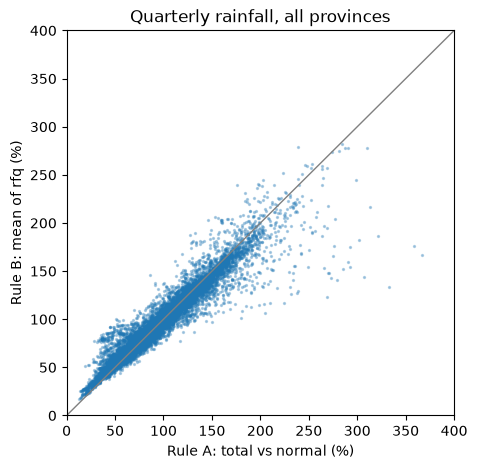

In [15]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(full["rule_a_pct"], full["rule_b_mean_rfq"], s=2, alpha=0.3)
ax.plot([0, 400], [0, 400], color="grey", linewidth=1)
ax.set_xlim(0, 400)
ax.set_ylim(0, 400)
ax.set_xlabel("Rule A: total vs normal (%)")
ax.set_ylabel("Rule B: mean of rfq (%)")
ax.set_title("Quarterly rainfall, all provinces")
plt.show()

## 5. First look: yield and rainfall over time

No models. Two large producers, picked by hand:
- Nueva Ecija (`PH03049`), Palay: the biggest rice province.
- Isabela (`PH02031`), Corn: a major corn province.

The PCODEs are typed in here because the lookup table does not exist yet. Shaded months are El Niño conditions (ONI at or above +0.5) from `data/processed/enso_monthly.csv`. Rainfall uses Rule A only to keep the plot simple.

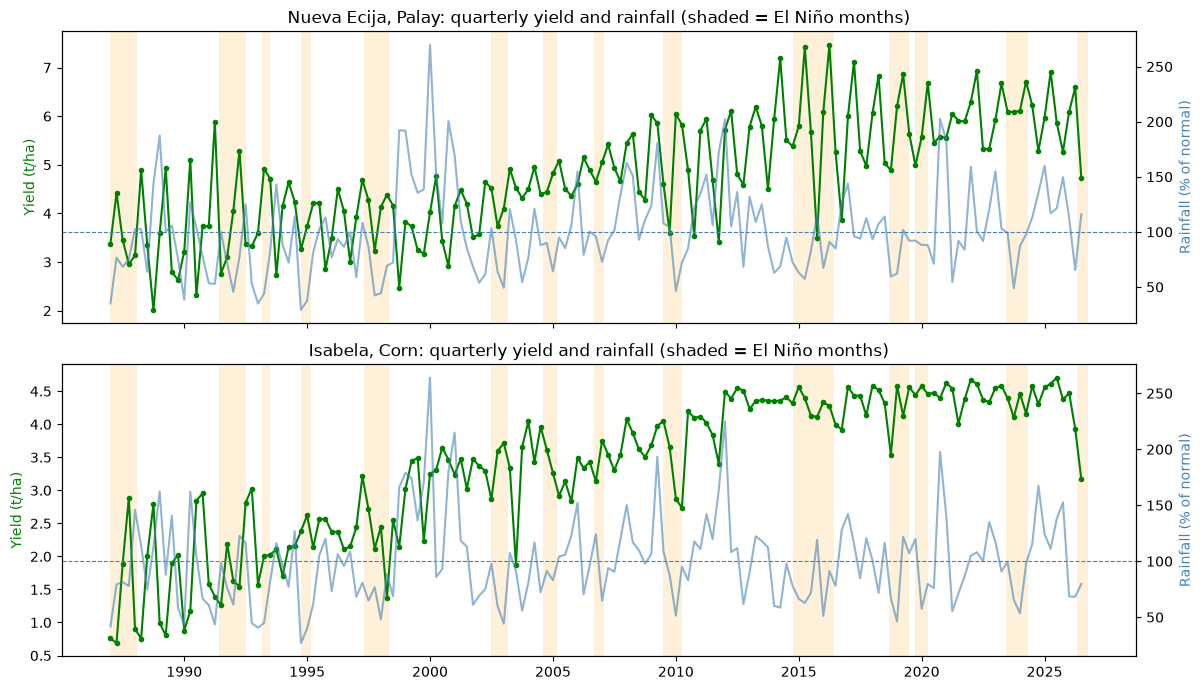

In [16]:
enso = pd.read_csv(ENSO_PATH, parse_dates=["date"])
warm_months = enso.loc[enso["oni"] >= 0.5, "date"]

EXAMPLES = [("Nueva Ecija", "PH03049", "Palay"), ("Isabela", "PH02031", "Corn")]
fig, axes = plt.subplots(len(EXAMPLES), 1, figsize=(12, 7), sharex=True)
for ax, (name, pcode, crop) in zip(axes, EXAMPLES):
    series = crops[(crops["province"] == name) & (crops["crop_type"] == crop)].copy()
    series["date"] = pd.PeriodIndex.from_fields(year=series["year"], quarter=series["quarter"]).to_timestamp()
    rain_series = full[full["PCODE"] == pcode].copy()
    rain_series["date"] = pd.PeriodIndex.from_fields(year=rain_series["year"], quarter=rain_series["quarter"]).to_timestamp()
    rain_series = rain_series[rain_series["year"] >= 1987]

    for month in warm_months[warm_months.dt.year >= 1987]:
        ax.axvspan(month, month + pd.DateOffset(months=1), color="orange", alpha=0.15, linewidth=0)
    ax.plot(series["date"], series["yield_t_per_ha"], marker=".", color="green")
    ax.set_ylabel("Yield (t/ha)", color="green")
    ax.set_title(f"{name}, {crop}: quarterly yield and rainfall (shaded = El Niño months)")
    rain_ax = ax.twinx()
    rain_ax.plot(rain_series["date"], rain_series["rule_a_pct"], color="steelblue", alpha=0.6)
    rain_ax.axhline(100, color="steelblue", linewidth=0.8, linestyle="--")
    rain_ax.set_ylabel("Rainfall (% of normal)", color="steelblue")
plt.tight_layout()
plt.show()

What the plot shows (a first look only):
- Yield moves a lot between quarters of the same year (wet and dry seasons), so a "normal" per calendar quarter is likely needed.
- Yield rises steadily over the 40 years (Nueva Ecija palay from about 3 to about 6 t/ha; Isabela corn from about 1 to about 4.5 t/ha), most likely from better seeds and farming. A plain 40-year average as "normal" would make every recent year look above normal, so the normal probably has to follow this trend.

## 6. Findings

**Cleaning**
- After cleaning there are 80 provinces and 6 crop types (480 province-crop pairs, 1,920 province-crop-quarter cells).
- The cleaned provinces add up to the national total in every quarter up to 2022.
- From 2023 on, part of BARMM is in the region total but in no province row. For total palay that is about 16,000 to 20,000 ha a year (2023 to 2025), and for total corn about 22,000 to 27,000 ha. The cause is not confirmed (one guess is the BARMM Special Geographic Area, but Cotabato's area shows no matching drop). This area cannot be given to any province.

**Usable data** (years with area > 0 and a yield, out of 40)

| Minimum years | Pairs passing (of 480) | Cells passing (of 1,920) |
| --- | --- | --- |
| 5 | 476 | 1,854 |
| 10 | 475 | 1,839 |
| 15 | 473 | 1,806 |
| 20 | 462 | 1,765 |
| 30 | 441 | 1,586 |

- Most pairs have the full 40 years. The thin ones are: Tawi-Tawi irrigated palay (0), Basilan yellow corn (0), Tawi-Tawi yellow corn (1), Sulu yellow corn (2), Batanes irrigated palay (5), Sulu irrigated palay (12), Dinagat Islands (13 to 18), Batanes (15).
- Many cells fail only because a crop is not planted in that quarter (for example Sulu palay is reported only in Quarter 3). Those are not missing data.
- Rainfed palay and yellow corn have the fewest cells with 30 or more years.

**Rainfall**
- 81 provinces, 1981-01-01 to 2026-11-01, no missing values. The 392 preliminary rows are October and November 2026.
- `rfh_avg` is a fixed normal for each ten-day period (the same every year).
- 81 quarters are incomplete (fewer than 9 periods): the current quarter, 2026 Quarter 4.
- Rule A (total vs normal) and Rule B (mean of rfq) agree closely: correlation 0.952, mean difference 6.3 points, 95% of quarters within 21.9 points. Rule B reads higher in dry quarters. Example, Nueva Ecija 2015 Quarter 2 (El Niño year): Rule A 57.4%, Rule B 69.9%.

**Yield trend**
- Yield rises strongly over 1987 to 2026 in both example provinces. The "province's own normal" will need to follow this trend rather than be a flat average.

**Not decided here:** the minimum years, the rainfall rule, how "normal" handles the trend, and what to do with the BARMM area that has no province.